# PSTH Classifier for rest_int Classification

**Target:** `rest_int` (0: 1min, 1: 5min, 2: 10min rest)

**Method:**
- **Euclidean Distance-Based** classifier: assign to nearest class centroid in PCA space
- **PCA** for dimensionality reduction
- **Hyperparameters:** bin_size [0.5, 1, 2] Hz, n_pc [2, 3, 4]
- **StratifiedKFold** for hyperparameter tuning
- **Grid Search** over hyperparameters
- **MCCV:** 10 random train/test splits by user_id

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.base import BaseEstimator, ClassifierMixin

In [10]:
class EuclideanDistanceClassifier(BaseEstimator, ClassifierMixin):
    """Assign each sample to the class with nearest centroid (Euclidean distance)."""

    def __init__(self, n_components=3, bin_size=1.0):
        self.n_components = n_components
        self.bin_size = bin_size
        self.pca_ = None
        self.scaler_ = None
        self.centroids_ = None
        self.classes_ = None

    def _rebin_psd(self, X_psd: np.ndarray, bin_size: float) -> np.ndarray:
        """Rebin PSD features. X_psd shape: (n_samples, n_per_ch * 3) for 1-450 Hz per channel."""
        n_samples = X_psd.shape[0]
        n_total = X_psd.shape[1]
        n_ch = 3
        n_per_ch = n_total // n_ch  # 450 for full PSD, 7 for bands
        X_rebinned = []
        for ch in range(n_ch):
            start = ch * n_per_ch
            end = (ch + 1) * n_per_ch
            psd_ch = X_psd[:, start:end]  # (n_samples, 450)
            if bin_size == 1.0:
                X_rebinned.append(psd_ch)
            elif bin_size == 2.0:
                # Average every 2 bins
                n_bins = n_per_ch // 2
                if n_bins < 1:
                    X_rebinned.append(psd_ch)
                else:
                    pad = n_per_ch - n_bins * 2
                    if pad > 0:
                        psd_ch = psd_ch[:, :-pad]
                    reshaped = psd_ch.reshape(n_samples, n_bins, 2)
                    rebinned = np.mean(reshaped, axis=2)
                    X_rebinned.append(rebinned)
            elif bin_size == 0.5:
                # Interpolate to 0.5 resolution (2x bins)
                x_old = np.arange(n_per_ch)
                n_new = n_per_ch * 2
                x_new = np.linspace(0, n_per_ch - 1, n_new)
                rebinned = np.array([
                    np.interp(x_new, x_old, psd_ch[i]) for i in range(n_samples)
                ])
                X_rebinned.append(rebinned)
            else:
                raise ValueError(f"bin_size must be 0.5, 1, or 2, got {bin_size}")
        return np.hstack(X_rebinned)

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)
        X_rebinned = self._rebin_psd(X, self.bin_size)
        self.scaler_ = StandardScaler()
        X_scaled = self.scaler_.fit_transform(X_rebinned)
        self.pca_ = PCA(n_components=self.n_components, random_state=42)
        X_pca = self.pca_.fit_transform(X_scaled)
        self.classes_ = np.unique(y)
        self.centroids_ = np.array([
            X_pca[y == c].mean(axis=0) for c in self.classes_
        ])
        return self

    def predict(self, X):
        X = np.asarray(X)
        X_rebinned = self._rebin_psd(X, self.bin_size)
        X_scaled = self.scaler_.transform(X_rebinned)
        X_pca = self.pca_.transform(X_scaled)
        dists = np.array([
            np.linalg.norm(X_pca - c, axis=1) for c in self.centroids_
        ])
        idx = np.argmin(dists, axis=0)
        return self.classes_[idx]


class EuclideanDistanceClassifierNoPCA(BaseEstimator, ClassifierMixin):
    """Same as EuclideanDistanceClassifier but uses scaled raw features (no PCA)."""

    def __init__(self, bin_size=1.0):
        self.bin_size = bin_size
        self.scaler_ = None
        self.centroids_ = None
        self.classes_ = None

    def _rebin_psd(self, X_psd: np.ndarray, bin_size: float) -> np.ndarray:
        n_samples = X_psd.shape[0]
        n_total = X_psd.shape[1]
        n_ch = 3
        n_per_ch = n_total // n_ch
        X_rebinned = []
        for ch in range(n_ch):
            start = ch * n_per_ch
            end = (ch + 1) * n_per_ch
            psd_ch = X_psd[:, start:end]
            if bin_size == 1.0:
                X_rebinned.append(psd_ch)
            elif bin_size == 2.0:
                n_bins = n_per_ch // 2
                if n_bins < 1:
                    X_rebinned.append(psd_ch)
                else:
                    pad = n_per_ch - n_bins * 2
                    if pad > 0:
                        psd_ch = psd_ch[:, :-pad]
                    reshaped = psd_ch.reshape(n_samples, n_bins, 2)
                    rebinned = np.mean(reshaped, axis=2)
                    X_rebinned.append(rebinned)
            elif bin_size == 0.5:
                x_old = np.arange(n_per_ch)
                n_new = n_per_ch * 2
                x_new = np.linspace(0, n_per_ch - 1, n_new)
                rebinned = np.array([np.interp(x_new, x_old, psd_ch[i]) for i in range(n_samples)])
                X_rebinned.append(rebinned)
            else:
                raise ValueError(f"bin_size must be 0.5, 1, or 2, got {bin_size}")
        return np.hstack(X_rebinned)

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)
        X_rebinned = self._rebin_psd(X, self.bin_size)
        self.scaler_ = StandardScaler()
        X_scaled = self.scaler_.fit_transform(X_rebinned)
        self.classes_ = np.unique(y)
        self.centroids_ = np.array([X_scaled[y == c].mean(axis=0) for c in self.classes_])
        return self

    def predict(self, X):
        X = np.asarray(X)
        X_rebinned = self._rebin_psd(X, self.bin_size)
        X_scaled = self.scaler_.transform(X_rebinned)
        dists = np.array([np.linalg.norm(X_scaled - c, axis=1) for c in self.centroids_])
        idx = np.argmin(dists, axis=0)
        return self.classes_[idx]

In [11]:
# Load data (use dataset_filtered_1_450.csv for full 1-450 Hz PSD)
# Fallback to dataset_filtered_bands.csv if 1_450 not available
import os

if os.path.exists("dataset_filtered_1_450.csv"):
    df = pd.read_csv("dataset_filtered_1_450.csv")
    # Feature columns: ch_1_1 ... ch_1_450, ch_2_1 ... ch_3_450
    meta_cols = ["user_id", "rest_int", "exp", "seq"]
    feature_cols = [c for c in df.columns if c not in meta_cols]
    print(f"Loaded dataset_filtered_1_450.csv: {len(df)} samples, {len(feature_cols)} features")
else:
    df = pd.read_csv("dataset_filtered_bands.csv")
    meta_cols = ["user_id", "rest_int", "exp", "seq"]
    feature_cols = [c for c in df.columns if c not in meta_cols]
    print(f"Loaded dataset_filtered_bands.csv (fallback): {len(df)} samples, {len(feature_cols)} features")
    print("Note: bin_size will aggregate bands; for full PSTH use dataset_filtered_1_450.csv")

unique_users = df["user_id"].unique()
n_users = len(unique_users)
n_train_users = int(n_users * 0.8)
n_test_users = n_users - n_train_users

print(f"MCCV split: {n_train_users} train users, {n_test_users} test users per run")

Loaded dataset_filtered_1_450.csv: 243 samples, 1350 features
MCCV split: 11 train users, 3 test users per run


In [12]:
# Grid Search with StratifiedKFold
# PCA exploration: total PCs and 80% variance before grid search (using bin_size=1 data)
X_full = df[feature_cols].values
X_scaled = StandardScaler().fit_transform(X_full)
max_pc = min(len(feature_cols), len(df) - 1)
pca_explore = PCA(n_components=max_pc, random_state=42).fit(X_scaled)
cumvar = np.cumsum(pca_explore.explained_variance_ratio_)
n_pc_80 = np.searchsorted(cumvar, 0.8) + 1  # 1-based count for 80% variance
print(f"Total PCs (max): {max_pc}")
print(f"PCs to capture 80% variance: {n_pc_80}")
print(f"Actual variance at {n_pc_80} PCs: {cumvar[n_pc_80-1]:.4f}")

# Hyperparameters: bin_size [0.5, 1, 2], n_components up to n_pc_80
n_pc_max = min(n_pc_80, 20, max_pc)  # use 80% variance as max, cap at 20
n_components_options = [n for n in [2, 3, 4, 5, 10, 15, 20] if n <= n_pc_max]
if n_pc_max > 20 and n_pc_max not in n_components_options:
    n_components_options.append(n_pc_max)
    n_components_options.sort()
if not n_components_options:
    n_components_options = [min(4, max_pc)]

param_grid = {
    "bin_size": [0.5, 1.0, 2.0],
    "n_components": n_components_options,
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
clf = EuclideanDistanceClassifier()

# Use dataset_filtered_1_450 for full PSTH; bands need 450*3 features for bin_size to work as intended
if len(feature_cols) != 1350:
    print("Warning: dataset_filtered_bands has 21 features. bin_size will rebin 7 bands per channel.")

Total PCs (max): 242
PCs to capture 80% variance: 3
Actual variance at 3 PCs: 0.8494


In [13]:
# MCCV: 10 random train/test splits by user_id
N_MCCV = 10
MCCV_SEEDS = list(range(42, 42 + N_MCCV))

mccv_f1 = []
mccv_acc = []
mccv_cm_list = []
best_params_list = []

for run, seed in enumerate(MCCV_SEEDS):
    np.random.seed(seed)
    shuffled_users = np.random.permutation(unique_users)
    train_users = shuffled_users[:n_train_users]
    test_users = shuffled_users[n_train_users:]

    train_mask = df["user_id"].isin(train_users)
    test_mask = df["user_id"].isin(test_users)
    df_train = df[train_mask]
    df_test = df[test_mask]

    X_train = df_train[feature_cols].values
    y_train = df_train["rest_int"].values
    X_test = df_test[feature_cols].values
    y_test = df_test["rest_int"].values

    grid_search = GridSearchCV(
        clf, param_grid, cv=cv, scoring="f1_weighted", n_jobs=-1, verbose=0
    )
    grid_search.fit(X_train, y_train)

    y_pred = grid_search.best_estimator_.predict(X_test)
    f1 = f1_score(y_test, y_pred, average="weighted")
    acc = (y_pred == y_test).mean()
    cm = confusion_matrix(y_test, y_pred)

    mccv_f1.append(f1)
    mccv_acc.append(acc)
    mccv_cm_list.append(cm)
    best_params_list.append(grid_search.best_params_)

    print(f"Run {run+1}/{N_MCCV} (seed={seed}): F1={f1:.4f}, Acc={acc:.4f}  best={grid_search.best_params_}")

Run 1/10 (seed=42): F1=0.2569, Acc=0.3137  best={'bin_size': 0.5, 'n_components': 2}
Run 2/10 (seed=43): F1=0.1972, Acc=0.2037  best={'bin_size': 0.5, 'n_components': 2}
Run 3/10 (seed=44): F1=0.4530, Acc=0.4630  best={'bin_size': 0.5, 'n_components': 3}
Run 4/10 (seed=45): F1=0.3143, Acc=0.3333  best={'bin_size': 0.5, 'n_components': 3}
Run 5/10 (seed=46): F1=0.3379, Acc=0.3333  best={'bin_size': 1.0, 'n_components': 3}
Run 6/10 (seed=47): F1=0.2317, Acc=0.2353  best={'bin_size': 0.5, 'n_components': 3}
Run 7/10 (seed=48): F1=0.2465, Acc=0.3148  best={'bin_size': 1.0, 'n_components': 3}
Run 8/10 (seed=49): F1=0.3160, Acc=0.3137  best={'bin_size': 1.0, 'n_components': 3}
Run 9/10 (seed=50): F1=0.2640, Acc=0.2778  best={'bin_size': 0.5, 'n_components': 3}
Run 10/10 (seed=51): F1=0.3206, Acc=0.3529  best={'bin_size': 0.5, 'n_components': 2}


In [14]:
# MCCV summary
print("--- MCCV Results (10 random train/test splits by user_id) ---")
print(f"Weighted F1: {np.mean(mccv_f1):.4f} ± {np.std(mccv_f1):.4f}")
print(f"Accuracy:     {np.mean(mccv_acc):.4f} ± {np.std(mccv_acc):.4f}")

mean_cm = np.mean(mccv_cm_list, axis=0).round(1)
print("\n--- Mean Confusion Matrix (across 10 runs) ---")
print(mean_cm)
print("(rows: 1min, 5min, 10min; cols: predicted)")

# Most frequent best params
from collections import Counter
param_strs = [str(p) for p in best_params_list]
most_common = Counter(param_strs).most_common(1)[0]
print(f"\nMost frequent best params: {most_common[0]} (in {most_common[1]}/10 runs)")

--- MCCV Results (10 random train/test splits by user_id) ---
Weighted F1: 0.2938 ± 0.0683
Accuracy:     0.3142 ± 0.0664

--- Mean Confusion Matrix (across 10 runs) ---
[[6.9 5.6 4.9]
 [6.5 4.6 6.3]
 [6.  6.9 5.1]]
(rows: 1min, 5min, 10min; cols: predicted)

Most frequent best params: {'bin_size': 0.5, 'n_components': 3} (in 4/10 runs)


## Comparison 1: With PCA vs Without PCA

MCCV 10 runs, paired comparison. Bar chart with significance (paired t-test).

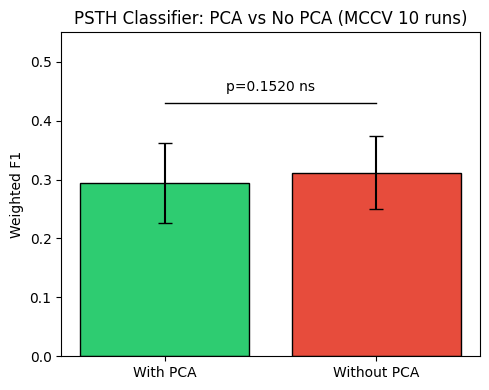

With PCA:  0.2938 ± 0.0683
Without PCA: 0.3116 ± 0.0623
Paired t-test: p = 0.1520 ns


In [15]:
# PCA vs Without PCA: MCCV 10 runs
param_with_pca = {"bin_size": [0.5, 1.0, 2.0], "n_components": n_components_options}
param_no_pca = {"bin_size": [0.5, 1.0, 2.0]}

f1_with_pca, f1_no_pca = [], []
for run, seed in enumerate(MCCV_SEEDS):
    np.random.seed(seed)
    shuffled_users = np.random.permutation(unique_users)
    train_users = shuffled_users[:n_train_users]
    test_users = shuffled_users[n_train_users:]
    train_mask = df["user_id"].isin(train_users)
    test_mask = df["user_id"].isin(test_users)
    X_train = df[train_mask][feature_cols].values
    y_train = df[train_mask]["rest_int"].values
    X_test = df[test_mask][feature_cols].values
    y_test = df[test_mask]["rest_int"].values

    gs_pca = GridSearchCV(EuclideanDistanceClassifier(), param_with_pca, cv=cv, scoring="f1_weighted", n_jobs=-1, verbose=0)
    gs_pca.fit(X_train, y_train)
    f1_with_pca.append(f1_score(y_test, gs_pca.best_estimator_.predict(X_test), average="weighted"))

    gs_no = GridSearchCV(EuclideanDistanceClassifierNoPCA(), param_no_pca, cv=cv, scoring="f1_weighted", n_jobs=-1, verbose=0)
    gs_no.fit(X_train, y_train)
    f1_no_pca.append(f1_score(y_test, gs_no.best_estimator_.predict(X_test), average="weighted"))

# Paired t-test
t_stat, p_val = stats.ttest_rel(f1_with_pca, f1_no_pca)
sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"

# Bar chart with significance
fig, ax = plt.subplots(figsize=(5, 4))
x = np.arange(2)
means = [np.mean(f1_with_pca), np.mean(f1_no_pca)]
stds = [np.std(f1_with_pca), np.std(f1_no_pca)]
ax.bar(x, means, yerr=stds, capsize=5, color=["#2ecc71", "#e74c3c"], edgecolor="black")
ax.set_xticks(x)
ax.set_xticklabels(["With PCA", "Without PCA"])
ax.set_ylabel("Weighted F1")
ax.set_title("PSTH Classifier: PCA vs No PCA (MCCV 10 runs)")
ymax = max(means) + max(stds) + 0.05
ax.plot([0, 1], [ymax, ymax], "k-", lw=1)
ax.text(0.5, ymax + 0.02, f"p={p_val:.4f} {sig}", ha="center", fontsize=10)
ax.set_ylim(0, ymax + 0.12)
plt.tight_layout()
plt.show()
print(f"With PCA:  {np.mean(f1_with_pca):.4f} ± {np.std(f1_with_pca):.4f}")
print(f"Without PCA: {np.mean(f1_no_pca):.4f} ± {np.std(f1_no_pca):.4f}")
print(f"Paired t-test: p = {p_val:.4f} {sig}")

## Comparison 2: Subject-specific vs Generalized Models

- **Generalized**: Train on 11 users, test on 3 held-out users
- **Subject-specific**: For each test user, train only on that user's data (with CV), test on held-out portion

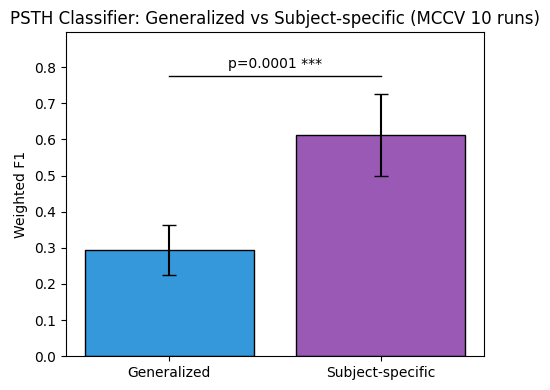

Generalized: 0.2938 ± 0.0683
Subject-specific: 0.6121 ± 0.1141
Paired t-test: p = 0.0001 ***


In [16]:
# Subject-specific vs Generalized: MCCV 10 runs
f1_generalized, f1_subject_specific = [], []
for run, seed in enumerate(MCCV_SEEDS):
    np.random.seed(seed)
    shuffled_users = np.random.permutation(unique_users)
    train_users = shuffled_users[:n_train_users]
    test_users = shuffled_users[n_train_users:]

    # Generalized
    train_mask = df["user_id"].isin(train_users)
    test_mask = df["user_id"].isin(test_users)
    X_train_g = df[train_mask][feature_cols].values
    y_train_g = df[train_mask]["rest_int"].values
    X_test_all = df[test_mask][feature_cols].values
    y_test_all = df[test_mask]["rest_int"].values
    gs_g = GridSearchCV(clf, param_grid, cv=cv, scoring="f1_weighted", n_jobs=-1, verbose=0)
    gs_g.fit(X_train_g, y_train_g)
    f1_generalized.append(f1_score(y_test_all, gs_g.best_estimator_.predict(X_test_all), average="weighted"))

    # Subject-specific
    f1_per_user = []
    for uid in test_users:
        df_u = df[df["user_id"] == uid]
        X_u = df_u[feature_cols].values
        y_u = df_u["rest_int"].values
        if len(y_u) < 6:
            f1_per_user.append(0.0)
            continue
        n_splits = min(3, len(y_u) // 6) or 2
        skf_u = StratifiedKFold(n_splits=max(2, n_splits), shuffle=True, random_state=42)
        preds, truths = [], []
        for tr_idx, te_idx in skf_u.split(X_u, y_u):
            gs_u = GridSearchCV(clf, param_grid, cv=2, scoring="f1_weighted", n_jobs=-1, verbose=0)
            gs_u.fit(X_u[tr_idx], y_u[tr_idx])
            preds.extend(gs_u.best_estimator_.predict(X_u[te_idx]))
            truths.extend(y_u[te_idx])
        f1_per_user.append(f1_score(truths, preds, average="weighted"))
    f1_subject_specific.append(np.mean(f1_per_user))

# Paired t-test
t_stat, p_val = stats.ttest_rel(f1_generalized, f1_subject_specific)
sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"

# Bar chart
fig, ax = plt.subplots(figsize=(5, 4))
x = np.arange(2)
means = [np.mean(f1_generalized), np.mean(f1_subject_specific)]
stds = [np.std(f1_generalized), np.std(f1_subject_specific)]
ax.bar(x, means, yerr=stds, capsize=5, color=["#3498db", "#9b59b6"], edgecolor="black")
ax.set_xticks(x)
ax.set_xticklabels(["Generalized", "Subject-specific"])
ax.set_ylabel("Weighted F1")
ax.set_title("PSTH Classifier: Generalized vs Subject-specific (MCCV 10 runs)")
ymax = max(means) + max(stds) + 0.05
ax.plot([0, 1], [ymax, ymax], "k-", lw=1)
ax.text(0.5, ymax + 0.02, f"p={p_val:.4f} {sig}", ha="center", fontsize=10)
ax.set_ylim(0, ymax + 0.12)
plt.tight_layout()
plt.show()
print(f"Generalized: {np.mean(f1_generalized):.4f} ± {np.std(f1_generalized):.4f}")
print(f"Subject-specific: {np.mean(f1_subject_specific):.4f} ± {np.std(f1_subject_specific):.4f}")
print(f"Paired t-test: p = {p_val:.4f} {sig}")

In [17]:
# Save results for model comparison
import json
import os

os.makedirs("model_results", exist_ok=True)
results = {
    "model": "psth_classifier",
    "f1_with_pca": [float(x) for x in f1_with_pca],
    "f1_no_pca": [float(x) for x in f1_no_pca],
    "f1_generalized": [float(x) for x in f1_generalized],
    "f1_subject_specific": [float(x) for x in f1_subject_specific],
}
with open("model_results/psth_classifier_results.json", "w") as f:
    json.dump(results, f, indent=2)
print("Saved psth_classifier results to model_results/psth_classifier_results.json")

Saved psth_classifier results to model_results/psth_classifier_results.json
